[**DISCLAIMER**]
The dataset used is downloaded from https://www.kaggle.com/datasets/janiobachmann/bank-marketing-dataset/data which in turn has given credit to [Moro et al., 2014] S. Moro, P. Cortez and P. Rita. A Data-Driven Approach to Predict the Success of Bank Telemarketing. Decision Support Systems, Elsevier, 62:22-31, June 2014

In [ ]:
#import file bank.csv into pandas df

import pandas as pd

df = pd.read_csv('bank.csv')
# Encode deposit subscription as booleans: yes -> True, no -> False.
df['deposit'] = df['deposit'].map({'yes': True, 'no': False})
df
    

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,True
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,True
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,True
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,True
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,False
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,False
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,False
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,False


In [4]:
# Check the target class distribution (deposit subscription).
target = df['deposit']
class_counts = target.value_counts().rename_axis('deposit')
class_distribution = class_counts.to_frame(name='count')
class_distribution['percentage'] = (class_counts / class_counts.sum() * 100).round(2)

print(f"Missing target values: {target.isna().sum():,}")
class_distribution

Missing target values: 0


,count,percentage
deposit,,
False,5873,52.62
True,5289,47.38


In [5]:
# Quantify imbalance among the observed, non-missing classes.
majority_class = class_counts.idxmax()
majority_baseline = class_counts.max() / class_counts.sum()

if len(class_counts) > 1:
    imbalance_ratio = class_counts.max() / class_counts.min()
    print(f"Majority-to-minority class ratio: {imbalance_ratio:.2f}:1 (1:1 is balanced)")
else:
    print("Only one observed class; a class imbalance ratio is not defined.")

print(f"Majority-class accuracy baseline (always predict '{majority_class}'): {majority_baseline:.2%}")

Majority-to-minority class ratio: 1.11:1 (1:1 is balanced)
Majority-class accuracy baseline (always predict 'False'): 52.62%


### Feature distributions

Inspect numeric histograms over the full observed range and categorical count plots. The target `deposit` is excluded.

In [6]:
import matplotlib.pyplot as plt

features = df.drop(columns='deposit')
numeric_features = features.select_dtypes(include='number')

numeric_summary = numeric_features.describe().T[['min', '25%', '50%', '75%', 'max']]
numeric_summary = numeric_summary.rename(columns={'50%': 'median'})
numeric_summary['skewness'] = numeric_features.skew()
numeric_summary['missing'] = numeric_features.isna().sum()
numeric_summary.round(2)

,min,25%,median,75%,max,skewness,missing
age,18.0,32.0,39.0,49.00,95.0,0.86,0
balance,-6847.0,122.0,550.0,1708.00,81204.0,8.22,0
day,1.0,8.0,15.0,22.00,31.0,0.11,0
duration,2.0,138.0,255.0,496.00,3881.0,2.14,0
campaign,1.0,1.0,2.0,3.00,63.0,5.55,0
pdays,-1.0,-1.0,-1.0,20.75,854.0,2.45,0
previous,0.0,0.0,0.0,1.00,58.0,7.34,0


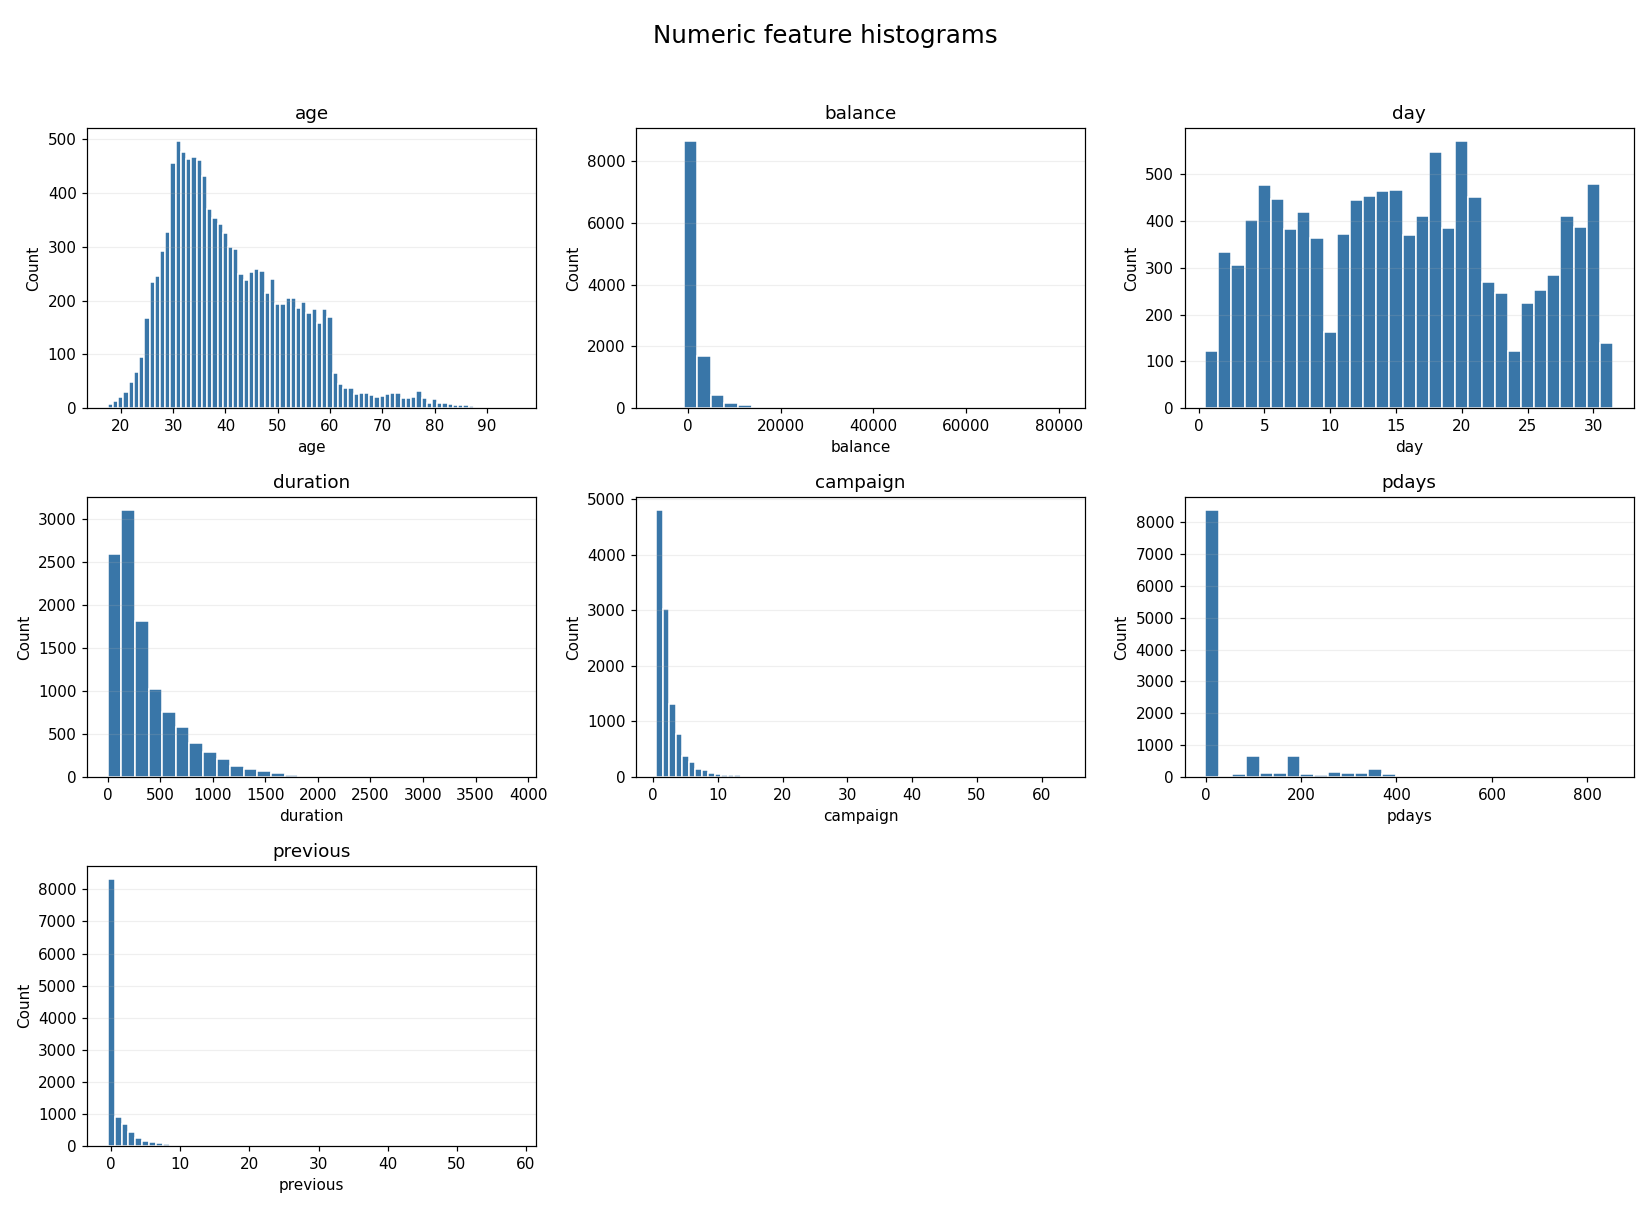

In [7]:
# Keep the full range so long tails and unusual values remain visible.
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, column in zip(axes.flat, numeric_features.columns):
    values = numeric_features[column].dropna()
    # Center bins on integers for age, day, and contact counts.
    bins = ([value - 0.5 for value in range(int(values.min()), int(values.max()) + 2)]
            if column in ['age', 'day', 'campaign', 'previous'] else 30)
    ax.hist(values, bins=bins, color='#3976a8', edgecolor='white')
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel('Count')
    ax.grid(axis='y', alpha=0.2)

for ax in axes.flat[len(numeric_features.columns):]:
    ax.set_visible(False)

fig.suptitle('Numeric feature histograms', fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

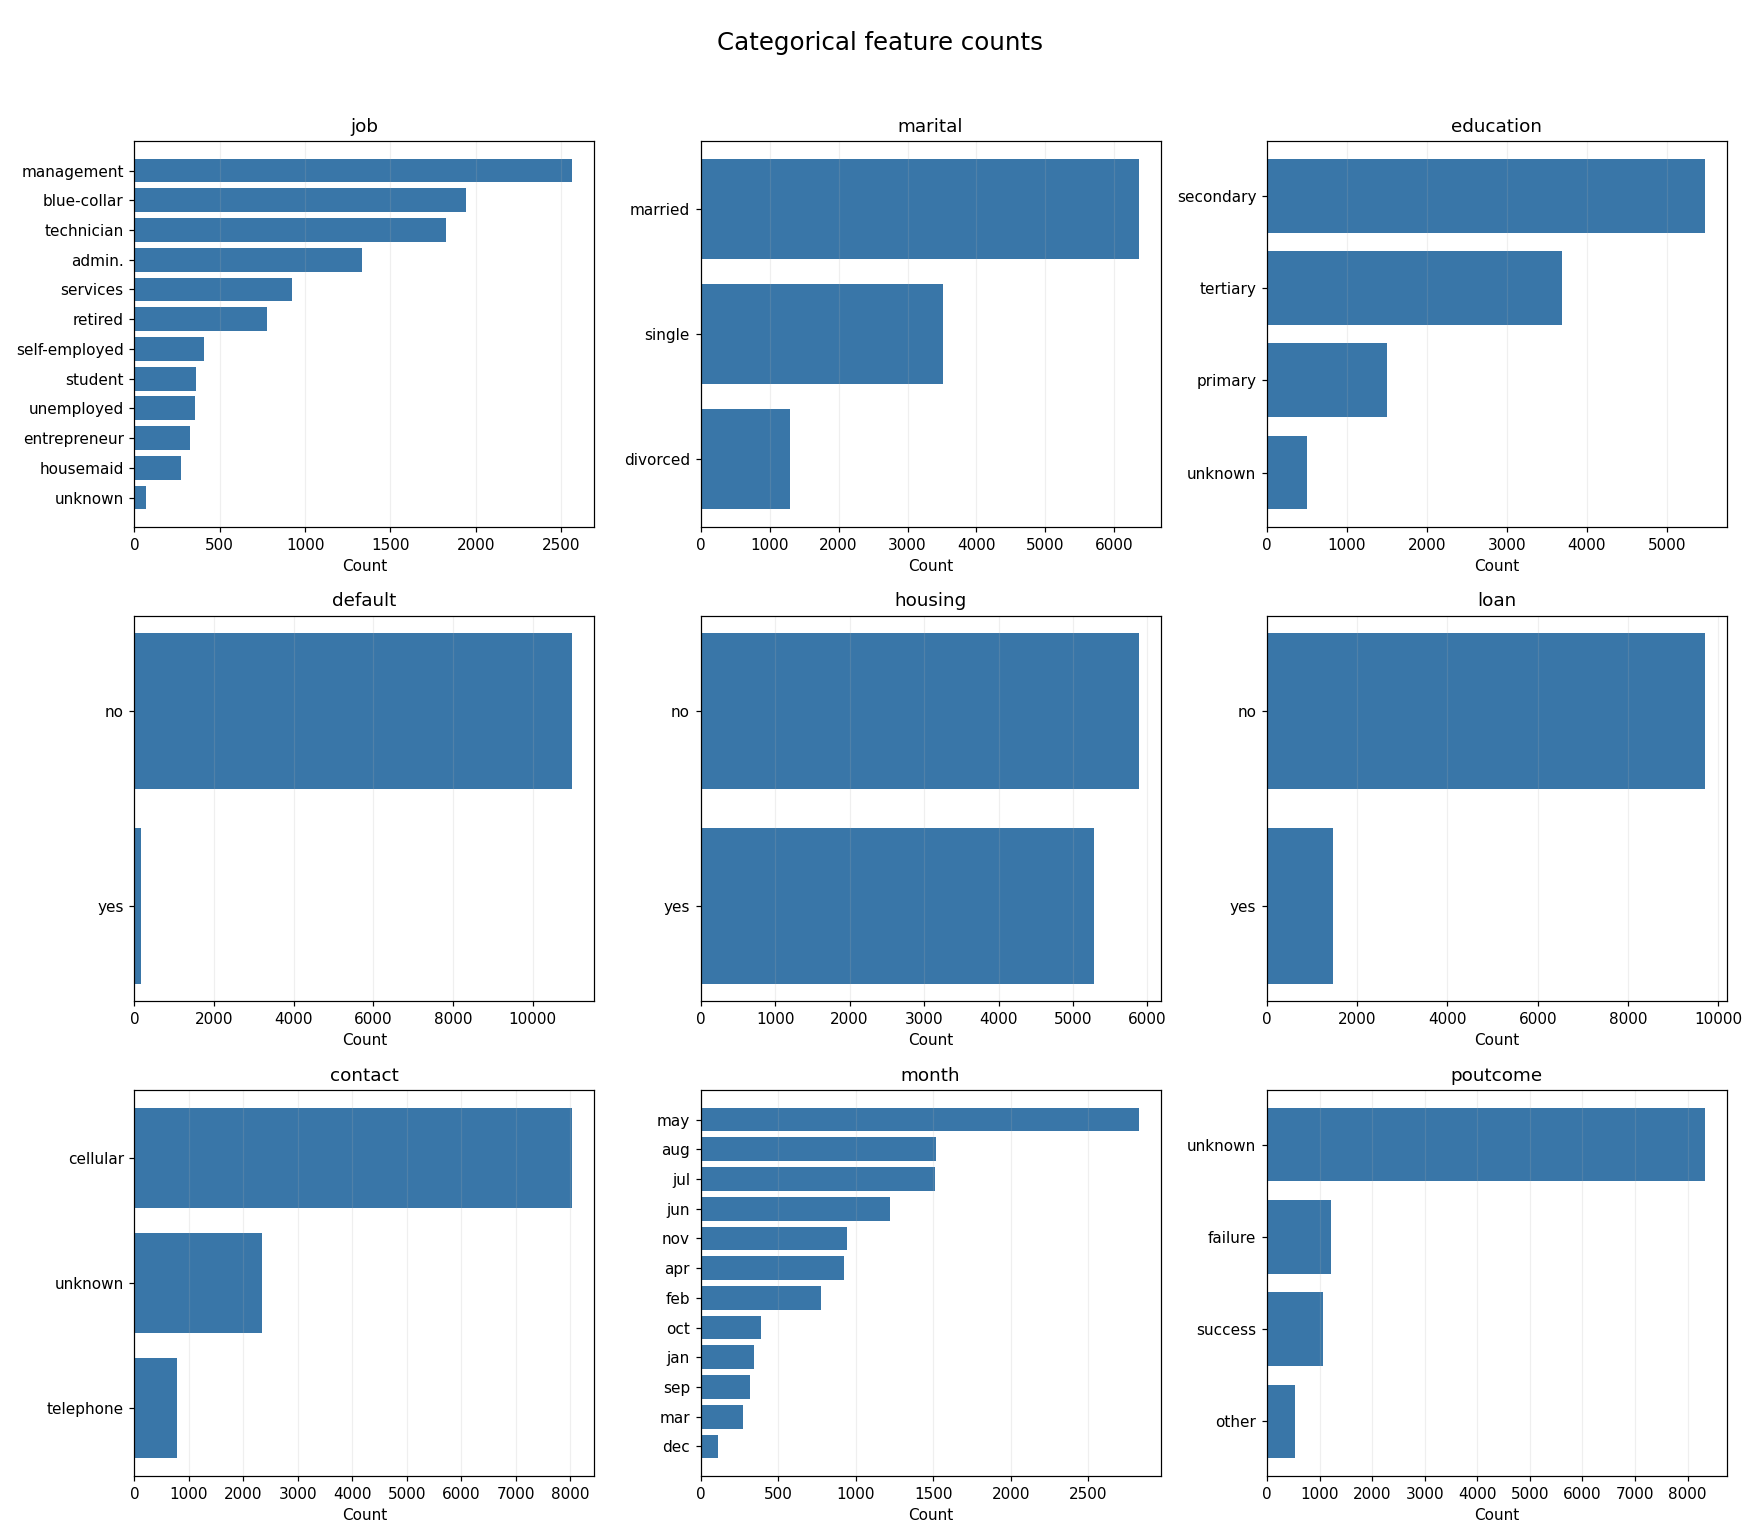

In [8]:
# Use category counts for nonnumeric features, including "unknown" values.
categorical_features = features.select_dtypes(exclude='number')
fig, axes = plt.subplots(3, 3, figsize=(16, 14))
for ax, column in zip(axes.flat, categorical_features.columns):
    counts = categorical_features[column].value_counts(dropna=False).sort_values()
    ax.barh(counts.index.astype(str), counts.values, color='#3976a8')
    ax.set_title(column)
    ax.set_xlabel('Count')
    ax.grid(axis='x', alpha=0.2)

for ax in axes.flat[len(categorical_features.columns):]:
    ax.set_visible(False)

fig.suptitle('Categorical feature counts', fontsize=16)
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

**Observations from this dataset**

- `balance`, `duration`, `campaign`, `pdays`, and `previous` have long right tails. `balance` ranges from -6,847 to 81,204, with a median of 550; investigate extremes before deciding on transformations.
- `pdays` is -1 for 8,324 rows (74.57%), and `previous` is zero for the same rows. Treat the -1 spike separately when interpreting the `pdays` distribution.
- `age` has a moderate right tail; `day` has relatively little skew.
- Categorical features can be concentrated even with a balanced target: `default` is overwhelmingly "no", and `poutcome` is mostly "unknown". There are no missing numeric values.

These plots preserve the original data; no rows are removed or values transformed.

### Prior-contact flag

Added `previously_contacted`: 1 when `pdays != -1`, otherwise 0. `pdays = -1` means no previous contact, so the flag distinguishes that group from actual elapsed days. The original `pdays` column is retained.

In [ ]:
df['previously_contacted'] = df['pdays'].ne(-1).astype('int8')

### Drop call length

Dropped `duration` because we do not know the call length before the call happens. This avoids using information unavailable when making a prediction.

In [ ]:
df = df.drop(columns='duration')
features = df.drop(columns='deposit')

### Outlier decisions before scaling

**Keep all 11,162 rows, with no log transforms or clipping.** We found no confirmed errors that justify deletion. The record review and validation comparison below support retaining rare customers. `features` keeps the original numeric magnitudes; its only recoding is the `pdays` placeholder. Earlier plots describe the values before that recoding.

| Feature | Decision | Brief reason |
| --- | --- | --- |
| `age` | Keep 18–95 unchanged. | No severe IQR flags; the oldest customers are retired, consistent with their ages. |
| `job` | Keep every category, including `unknown`. | Rare occupations are valid groups; unknown records missing information. |
| `marital` | Keep every category. | All observed marital-status categories are valid. |
| `education` | Keep every category, including `unknown`. | Less common levels and missing-information labels are not data errors. |
| `default` | Keep both values. | The 168 defaults are rare but describe a meaningful credit condition. |
| `balance` | Keep −6,847 to 81,204 unchanged. | Debt and high savings are plausible; reviewed extremes have coherent accompanying attributes. |
| `housing` | Keep both values. | Having or not having a housing loan is valid. |
| `loan` | Keep both values. | Personal-loan status is a valid binary feature. |
| `contact` | Keep every category, including `unknown`. | Telephone contacts and missing channel information are valid groups. |
| `day` | Keep 1–31 unchanged. | All values are valid day-of-month numbers. |
| `month` | Keep every month. | Uneven counts can reflect campaign scheduling, not erroneous months. |
| `campaign` | Keep 1–63 unchanged. | Repeated outreach is documented; there is no verified maximum that makes these counts invalid. |
| `pdays` | Keep actual elapsed days (1–854); use 0 for the −1 sentinel in `features`. | Long gaps are plausible; `previously_contacted` identifies the placeholder as no prior contact. |
| `previous` | Keep 0–58 unchanged. | Zero is structural no-history; positive counts require separate review, with no confirmed errors. |
| `poutcome` | Keep every category, including `unknown` and `other`. | These are valid outcome labels; unknown does not always mean no prior contact. |
| `previously_contacted` | Keep 0/1 unchanged. | This flag distinguishes no history from observed elapsed days. |

**Why we did not delete the severe tails:** an all-customer 3 × IQR rule would remove 1,311 rows (11.75%). Most customers have no previous contacts, so it flags `previous > 4`. Among customers with history, the corresponding cutoff is `previous > 13`, flagging 46 rather than 579 records. With that correction, the combined rule still flags 806 rows (7.22%). These are review flags, not established errors.

Reviewed examples: the minimum balance (−6,847) accompanies `default=yes` and a personal loan. The maximum (81,204) appears in two records with matching demographics and different contact histories; that supports plausibility without proving customer identity. The only severe `pdays` flag is 854 days, just 12 days above the next value of 842; dropping it at an 850-day statistical fence has no established business justification. There are no exact duplicate rows, missing values, negative contact counts, or disagreements between `pdays = -1` and `previous = 0`.

`deposit` remains the boolean target and is excluded from `features`. Fit any later scaler on training data only. Robust scaling can stabilize the estimated center and scale but still leaves extreme observations extreme; it is not a substitute for assessing model sensitivity.


In [ ]:
# Retain raw magnitudes; the outlier review does not justify deletion or compression.
features = df.drop(columns='deposit').copy()
# Zero is a placeholder for no prior contact, identified by previously_contacted.
features['pdays'] = features['pdays'].replace(-1, 0)


### Encode categorical features

Keep `unknown` as a separate category for `job`, `education`, `contact`, and `poutcome`, rather than guessing replacements or dropping customers. One-hot encoding gives each category its own 0/1 column, including an explicit `_unknown` column. No additional missing-value flags are needed.

Use a reproducible 80/20 split, stratified by `deposit`. Fit the encoder on training data only and reuse it for the test data. Previously unseen categories produce all zeros for that feature; the literal `unknown` is a normal learned category. Numeric features retain their raw magnitudes. Later, fit a scaler on the training numeric columns only and leave the one-hot columns unscaled.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

X_train, X_test, y_train, y_test = train_test_split(
    features, df['deposit'], test_size=0.2, stratify=df['deposit'], random_state=42
)
categorical_columns = features.select_dtypes(exclude=['number', 'bool']).columns.tolist()
numeric_columns = features.select_dtypes(include=['number', 'bool']).columns.tolist()

categorical_encoder = OneHotEncoder(
    drop=None, handle_unknown='ignore', sparse_output=False, dtype='int8'
).set_output(transform='pandas')

X_train_encoded = pd.concat([
    X_train[numeric_columns],
    categorical_encoder.fit_transform(X_train[categorical_columns]),
], axis=1)
X_test_encoded = pd.concat([
    X_test[numeric_columns],
    categorical_encoder.transform(X_test[categorical_columns]),
], axis=1)

print(f'Training: {len(X_train_encoded):,} rows; test: {len(X_test_encoded):,} rows')
print(f'Encoded features: {X_train_encoded.shape[1]} (numeric columns remain unscaled)')
unknown_columns = ['job_unknown', 'education_unknown', 'contact_unknown', 'poutcome_unknown']
pd.DataFrame({
    'training_unknown': X_train_encoded[unknown_columns].sum(),
    'test_unknown': X_test_encoded[unknown_columns].sum(),
})


Training: 8,929 rows; test: 2,233 rows
Encoded features: 51 (numeric columns remain unscaled)


,training_unknown,test_unknown
job_unknown,54,16
education_unknown,414,83
contact_unknown,1876,470
poutcome_unknown,6643,1683


### Correlated feature columns

Check training data only, excluding the `deposit` target. Pearson measures linear association; Spearman measures rank association and is useful alongside Pearson for the skewed numeric features. The heatmaps show the seven numeric features; the pair table checks all 51 encoded columns. Flag `|correlation| >= 0.80` for review, without automatically dropping columns. Scaling is not needed to calculate these correlations.


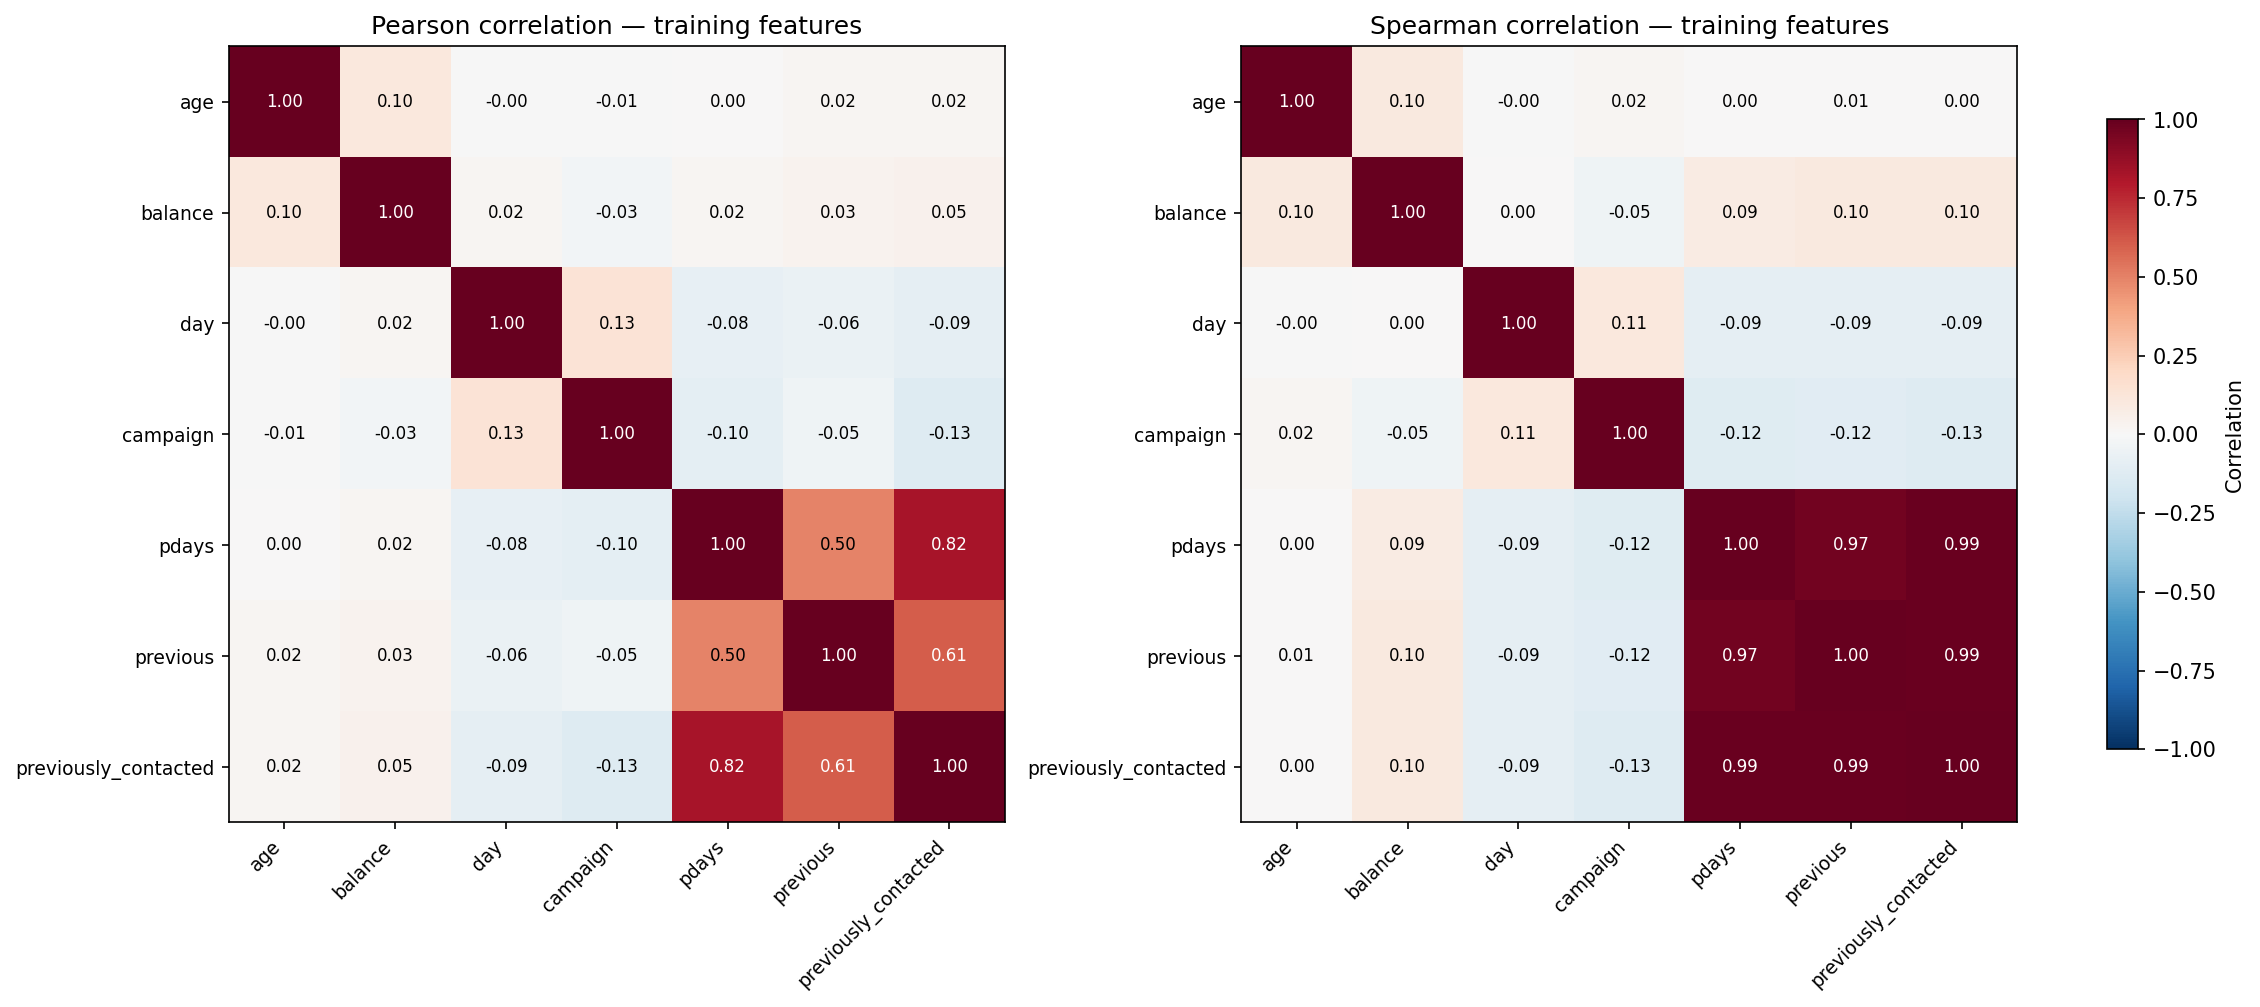

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

numeric_correlations = {
    'Pearson': X_train_encoded[numeric_columns].corr(method='pearson'),
    'Spearman': X_train_encoded[numeric_columns].corr(method='spearman'),
}
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5), constrained_layout=True)
for ax, (method, correlation) in zip(axes, numeric_correlations.items()):
    image = ax.imshow(correlation, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(numeric_columns)), numeric_columns, rotation=45, ha='right', fontsize=9)
    ax.set_yticks(range(len(numeric_columns)), numeric_columns, fontsize=9)
    ax.set_title(f'{method} correlation — training features')
    for row in range(len(numeric_columns)):
        for column in range(len(numeric_columns)):
            value = correlation.iloc[row, column]
            ax.text(column, row, f'{value:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if abs(value) >= 0.6 else 'black')
fig.colorbar(image, ax=axes, shrink=0.8, label='Correlation')
plt.show()


In [ ]:
encoded_pearson = X_train_encoded.corr(method='pearson')
encoded_spearman = X_train_encoded.corr(method='spearman')
upper_triangle = np.triu(np.ones(encoded_pearson.shape, dtype=bool), k=1)
correlation_pairs = pd.concat([
    encoded_pearson.where(upper_triangle).stack().rename('pearson'),
    encoded_spearman.where(upper_triangle).stack().rename('spearman'),
], axis=1).rename_axis(['feature_1', 'feature_2']).reset_index()

# Identify indicator pairs belonging to the same original categorical feature.
column_sources = {
    column: next((source for source in categorical_columns if column.startswith(f'{source}_')), column)
    for column in X_train_encoded.columns
}
correlation_pairs['relationship'] = np.where(
    correlation_pairs['feature_1'].map(column_sources).eq(correlation_pairs['feature_2'].map(column_sources)),
    'same original feature', 'different original features',
)
correlation_pairs['max_abs_correlation'] = correlation_pairs[['pearson', 'spearman']].abs().max(axis=1)
correlation_threshold = 0.80
high_correlation_pairs = correlation_pairs.loc[
    correlation_pairs['max_abs_correlation'].ge(correlation_threshold)
].sort_values('max_abs_correlation', ascending=False).reset_index(drop=True)
print(f"Pairs above the review threshold: {len(high_correlation_pairs)} (Pearson or Spearman)")
high_correlation_pairs.drop(columns='max_abs_correlation').round(4)


Pairs above the review threshold: 10 (Pearson or Spearman)


,feature_1,feature_2,pearson,spearman,relationship
0,loan_no,loan_yes,-1.0000,-1.0000,same original feature
1,default_no,default_yes,-1.0000,-1.0000,same original feature
2,housing_no,housing_yes,-1.0000,-1.0000,same original feature
3,previously_contacted,poutcome_unknown,-0.9997,-0.9997,different original features
4,previous,previously_contacted,0.6066,0.9863,different original features
5,previous,poutcome_unknown,-0.6065,-0.9861,different original features
6,pdays,previously_contacted,0.8236,0.9856,different original features
7,pdays,poutcome_unknown,-0.8234,-0.9853,different original features
8,pdays,previous,0.4969,0.9687,different original features
9,contact_cellular,contact_unknown,-0.8287,-0.8287,same original feature


In [ ]:
# Separate shared no-history zeros from relationships within observed histories.
history_columns = ['pdays', 'previous']
contacted_training_rows = X_train_encoded['previously_contacted'].eq(1)
history_correlation = pd.DataFrame([
    {
        'population': label, 'rows': len(values),
        'pearson': values[history_columns].corr(method='pearson').iloc[0, 1],
        'spearman': values[history_columns].corr(method='spearman').iloc[0, 1],
    }
    for label, values in [
        ('All training customers', X_train_encoded),
        ('Previously contacted only', X_train_encoded.loc[contacted_training_rows]),
    ]
]).set_index('population')
history_correlation.round(4)


,rows,pearson,spearman
population,,,
All training customers,8929,0.4969,0.9687
Previously contacted only,2287,-0.0060,-0.1245


**Findings and interpretation**

- `default_no`/`default_yes`, `housing_no`/`housing_yes`, and `loan_no`/`loan_yes` have correlation −1: each pair encodes opposite values of one feature. `contact_cellular`/`contact_unknown` is also strongly negative because categories are mutually exclusive.
- `previously_contacted` and `poutcome_unknown` are nearly complementary (Pearson −0.9997). Only one previously contacted training customer has an unknown prior outcome, so this is genuine near-redundancy to revisit during model selection.
- `pdays` and `previous` have overall Spearman correlation 0.9687, largely from shared no-history zeros. Among the 2,287 previously contacted training customers, Pearson is −0.0060 and Spearman is −0.1245. Keep elapsed days and contact counts for now: they measure different aspects of known histories.
- The other strong correlations involve this same history/no-history distinction. No columns are removed by these diagnostic cells. Low pairwise correlation does not rule out nonlinear or multi-column dependencies.

Because `drop=None` retains every one-hot category, each categorical block sums to 1 and creates linear dependence with an intercept, even when individual pairs are not strongly correlated. Choose reference categories or suitable regularization when selecting the model; the correlation threshold alone is not a deletion rule.
